In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 


#Some code to beautify the plots
plt.rcParams['figure.figsize'] = [10, 5]
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14

# Some of the images taken from the book - Deblurring images: Matrices, Spectra, and Filtering
#https://epubs.siam.org/doi/book/10.1137/1.9780898718874 


# Need to install tomopy to run this code. try `pip install tomopy'
from tomopy.misc import phantom

### Point Spread Function

Let $\mathbf{A} = [\mathbf{a}_1,\dots,\mathbf{a}_n]$ be the blurring operator.

We can rewrite the blurring equation $\mathbf{Ax} = \mathbf{b}$ as 
$$ x_1 \mathbf{a}_1 + \dots + x_n \mathbf{a}_n = \mathbf{b} .$$



In [2]:
from IPython.display import Image
from IPython.core.display import HTML 
Image(url= "figs/psf.png")

The left panel denotes a point source and the right panel denotes the point spread function. There are different types of blurring operators.

In [3]:
Image(url= "figs/blur_psf.png")

Here is some examples of pictures I took that has blurring but for artistic reasons!

In [4]:
Image(url= "figs/pan.jpg", width=500, height=500)

In [5]:
Image(url= "figs/bee.jpg", width=500, height=500)

### Define blurring operator

In [6]:
def blur(N, band = 3,sigma = 0.7, phant = 'shepp'):
    from scipy.linalg import toeplitz
    from scipy.sparse import csr_matrix, kron
    
    z = np.exp(-np.arange(band)**2./(2*sigma**2.))
    z = np.hstack((z.reshape((1,-1)), np.zeros((1,N-band), dtype = 'd')))

    A = toeplitz(z)
    A = csr_matrix(A)
    A = (1./(2.*np.pi*sigma**2.))*kron(A,A)

    if phant == 'blank':
        xtrue = 0.5 + np.zeros((N**2,), dtype = 'd')
    elif phant == 'barbara':
        x = phantom.barbara(N, dtype = 'd')
        xtrue = x.squeeze().reshape((-1,))
    elif phant == 'cameraman':
        x = phantom.cameraman(N, dtype = 'd')
        xtrue = x.squeeze().reshape((-1,))
    elif phant == 'checkerboard':
        x = phantom.checkerboard(N, dtype = 'd')
        xtrue = x.squeeze().reshape((-1,))
    elif phant == 'peppers':
        x = phantom.peppers(N, dtype = 'd')
        xtrue = x.squeeze().reshape((-1,))
    elif phant == 'shepp':
        x = phantom.shepp2d(N, dtype = 'd')
        xtrue = x.squeeze().reshape((-1,))
   
    b = A.dot(xtrue)

    return A, b, xtrue

### Construct test problem and add noise

Noise to signal ratio 0.030095890405259878


Text(0.5, 1.0, 'Blur + noise image')

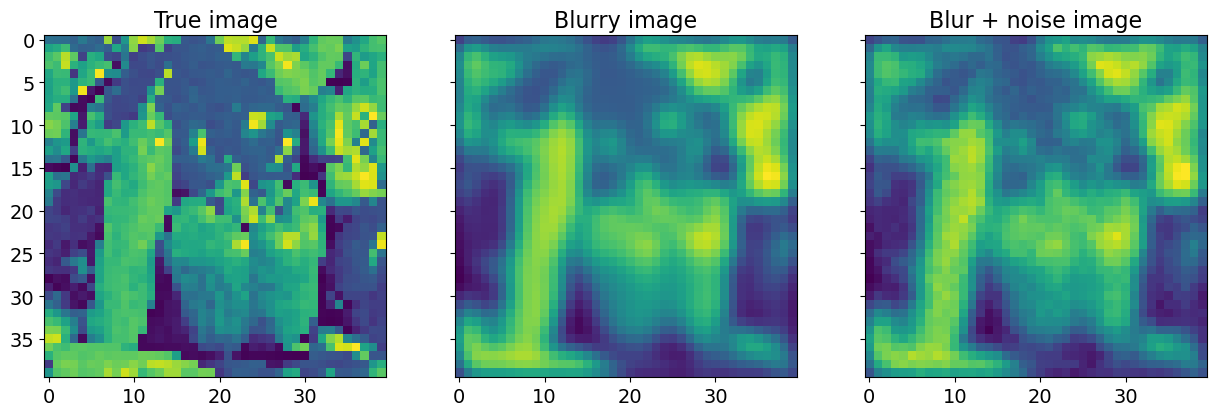

In [7]:
n = 40
A, b, xtrue = blur(n, band = 10, sigma = 1.3, phant = 'peppers')
A = A.todense()


noise = 0.03*np.linalg.norm(b)*np.random.randn(b.size)/np.sqrt(b.size)
bn = b + noise
print("Noise to signal ratio", np.linalg.norm(noise)/np.linalg.norm(b))

bn = bn[:,np.newaxis]

f, (ax1,ax2,ax3) = plt.subplots(1,3, sharey = True, figsize = (15,5))
ax1.imshow(xtrue.reshape(n,n))
ax1.set_title('True image', fontsize = 16)

ax2.imshow(b.reshape(n,n))
ax2.set_title('Blurry image', fontsize = 16)

ax3.imshow(bn.reshape(n,n))
ax3.set_title('Blur + noise image', fontsize = 16)


### Plot the naive solution

Text(0.5, 1.0, 'Naive solution')

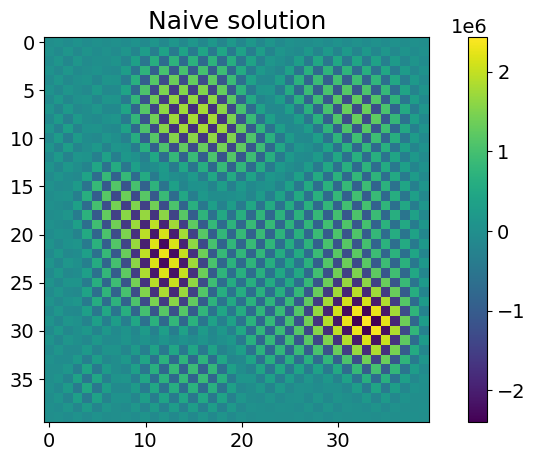

In [8]:
xn = np.linalg.solve(A,bn)

plt.figure()
plt.imshow(xn.reshape(n,n))
plt.colorbar()
plt.title('Naive solution', fontsize = 18)

### Analysis of the ill-conditioning

The condition number of the matrix is  3662076.0327224145


Text(0.5, 1.0, 'Singular values ')

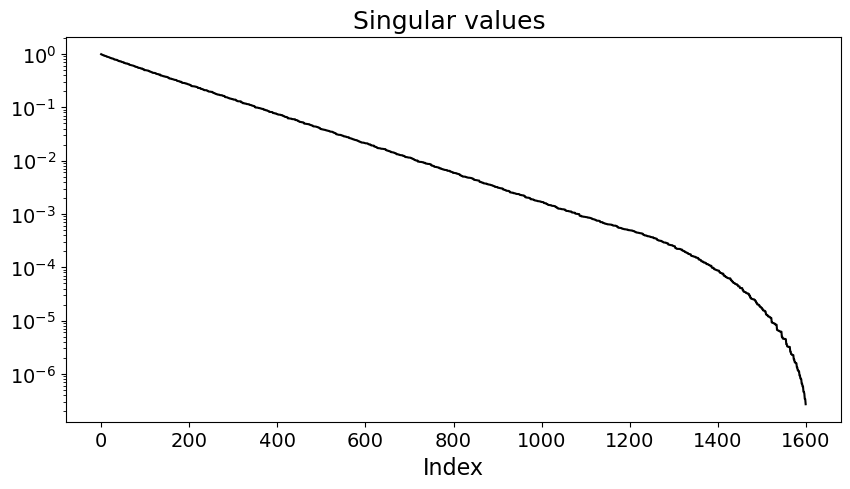

In [9]:
print("The condition number of the matrix is ",  np.linalg.cond(A))
u,s,vh = np.linalg.svd(A, full_matrices = False)
plt.figure()
plt.semilogy(s, 'k-')
plt.xlabel('Index', fontsize = 16)
plt.title('Singular values ', fontsize = 18)

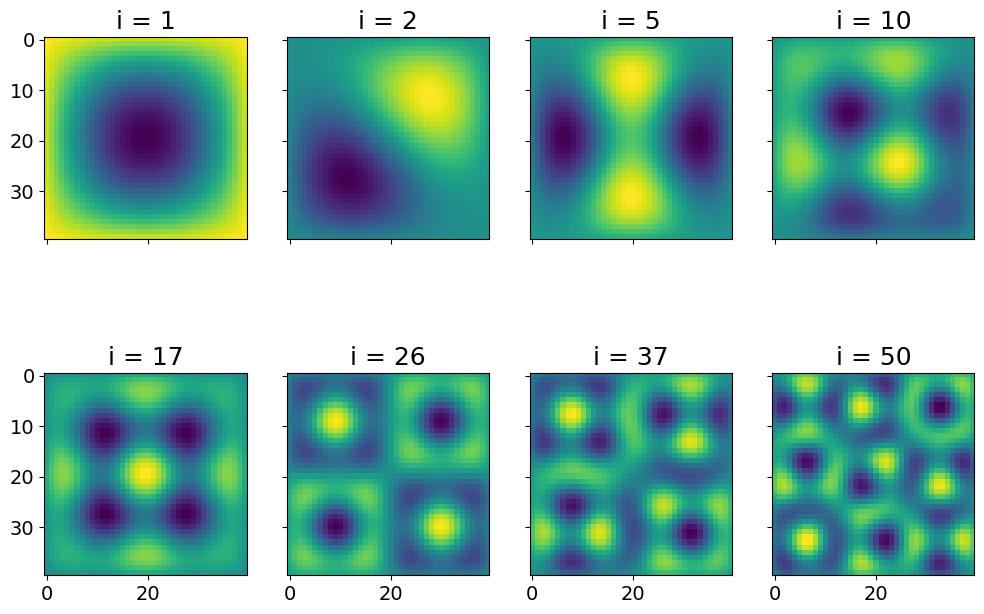

In [10]:
v = vh.T
f, axarray = plt.subplots(2,4,sharex = True, sharey = True, figsize = (12,8))
for i, ax in enumerate(axarray.flatten()):
    ax.imshow(v[:,i**2].reshape(n,n), )
    ax.set_title('i = ' + str(i**2+1), fontsize = 18)

### Truncated SVD solution

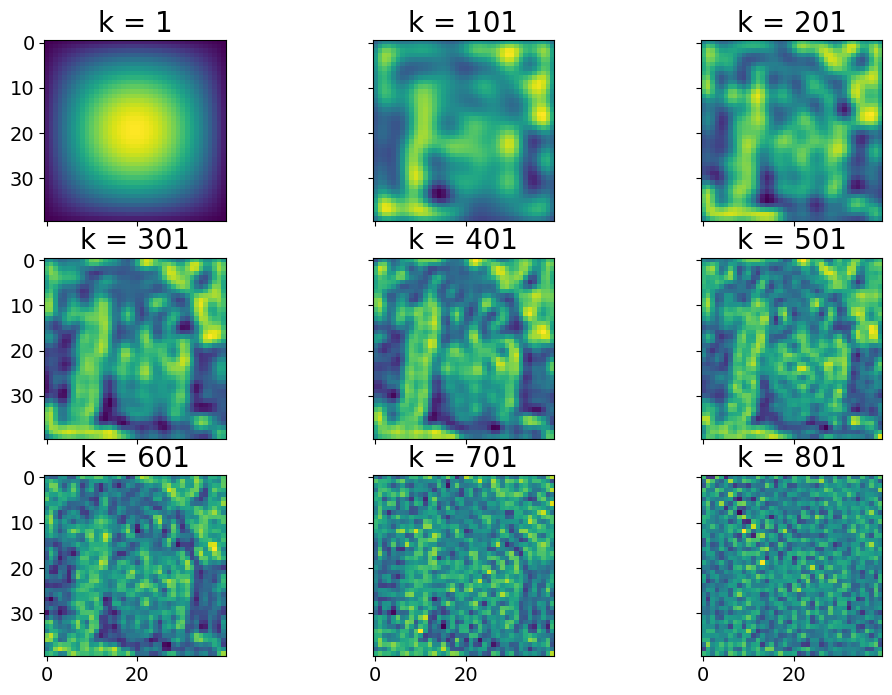

In [11]:
klst = range(1,900,100)

err = np.zeros((len(klst),), dtype = 'd')

f, axarray = plt.subplots(3,3, sharex = True, sharey = True, figsize = (12,8))

for i, ax in enumerate(axarray.flatten()):
    k = klst[i]
    uk = u[:,:k]; sk = s[:k]; vhk = vh[:k,:]
    xk = vhk.T @ (np.diag(1/sk) @ (uk.T @ bn))
    
    err[i] = np.linalg.norm(xk.flatten()-xtrue.flatten())
    
    ax.imshow( xk.reshape(n,n))
    ax.set_title('k = ' + str(k), fontsize = 20)

### plot the error in the reconstructions

Text(0.5, 1.0, 'Relative error vs k')

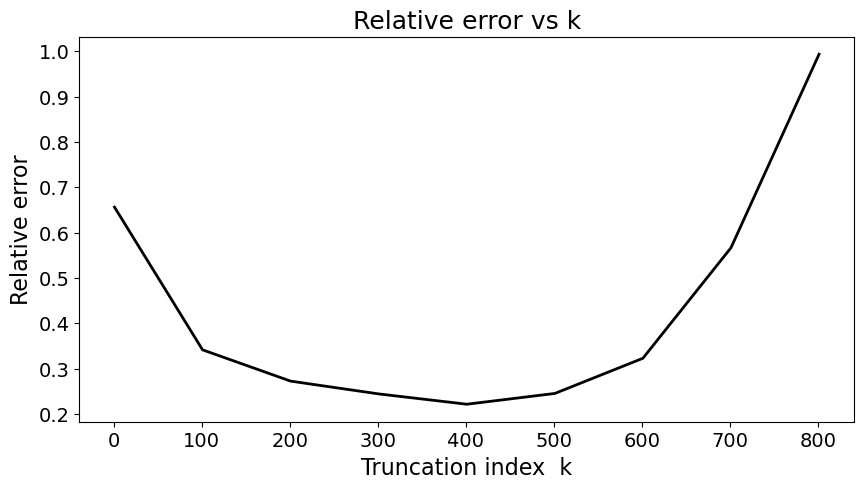

In [12]:
err /= np.linalg.norm(xtrue)
plt.plot(np.array(klst),err, 'k-', linewidth = 2.0)
plt.ylabel('Relative error', fontsize = 16)
plt.xlabel('Truncation index  k', fontsize = 16)
plt.title('Relative error vs k', fontsize = 18)

In [13]:
print("The index with lowest error is k =", klst[np.argmin(err)])
                    

The index with lowest error is k = 401


### Effect of increasing blurring

In [14]:
Image(url = "figs/svd_values.png", width = 700, height = 700)

### Learn more about deblurring and inverse problems

In [15]:
Image(url = "figs/books.png")
